Task 1 — Data Acquisition and Exploration

Step 1 — Install Required Libraries

In [1]:
!pip -q install wfdb scipy scikit-learn seaborn tensorflow

Step 2 — Import Libraries

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb

from scipy.signal import butter, sosfiltfilt
from collections import Counter
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, precision_recall_fscore_support
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, SimpleRNN, LSTM, GRU,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Step 3 — Download MIT-BIH Arrhythmia Dataset

In [3]:
DATA_DIR = "/content/mitdb"
os.makedirs(DATA_DIR, exist_ok=True)

wfdb.dl_database("mitdb", DATA_DIR)

records = wfdb.get_record_list("mitdb")

print("Total ECG recordings:", len(records))
print("Record IDs:", records)

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

Step 4 — Visualize a Raw ECG Signal

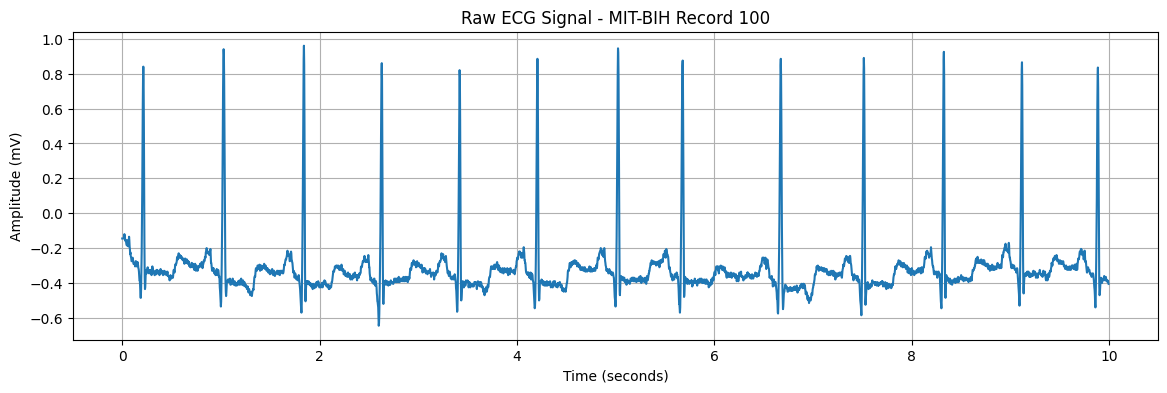

Sampling frequency: 360
Signal shape: (650000, 2)
Channels: ['MLII', 'V5']
Annotations: 2274


In [4]:
record = wfdb.rdrecord(f"{DATA_DIR}/100")
annotation = wfdb.rdann(f"{DATA_DIR}/100", "atr")

fs = record.fs
ecg = record.p_signal[:, 0]

plt.figure(figsize=(14, 4))
plt.plot(np.arange(3600) / fs, ecg[:3600])

plt.title("Raw ECG Signal - MIT-BIH Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid()
plt.show()

print("Sampling frequency:", fs)
print("Signal shape:", record.p_signal.shape)
print("Channels:", record.sig_name)
print("Annotations:", len(annotation.sample))

Step 5 — Define AAMI Classes and Exclude Paced Records

In [5]:
AAMI = {
    "N": "N", "L": "N", "R": "N",
    "e": "N", "j": "N",

    "A": "S", "a": "S", "J": "S",
    "S": "S",

    "V": "V", "E": "V",

    "F": "F",

    "/": "Q", "f": "Q",
    "Q": "Q", "?": "Q"
}

classes = ["N", "S", "V", "F", "Q"]
class_to_id = {c: i for i, c in enumerate(classes)}

paced_records = {"102", "104", "107", "217"}

valid_records = [
    r for r in records if r not in paced_records
]

print("Records after excluding paced records:",
      len(valid_records))
print("AAMI classes:", classes)

Records after excluding paced records: 44
AAMI classes: ['N', 'S', 'V', 'F', 'Q']


Task 2 — Data Preprocessing

Step 6 — Apply Bandpass Filtering (0.5–40 Hz)

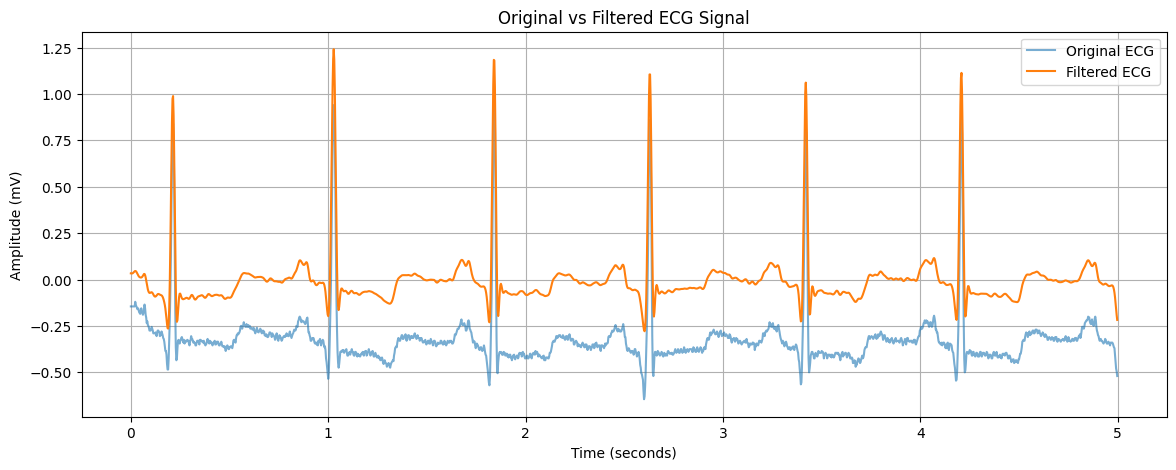

In [6]:
def filter_ecg(signal, fs=360):
    sos = butter(
        4,
        [0.5, 40],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, signal)

filtered_ecg = filter_ecg(ecg, fs)

plt.figure(figsize=(14, 5))

plt.plot(
    np.arange(1800) / fs,
    ecg[:1800],
    label="Original ECG",
    alpha=0.6
)

plt.plot(
    np.arange(1800) / fs,
    filtered_ecg[:1800],
    label="Filtered ECG",
    linewidth=1.5
)

plt.title("Original vs Filtered ECG Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid()
plt.show()

Step 7 — Segment ECG Beats Around R-Peaks

In [7]:
WINDOW = 256
HALF = WINDOW // 2

X = []
y = []
groups = []

for rec_id in valid_records:
    record = wfdb.rdrecord(f"{DATA_DIR}/{rec_id}")
    ann = wfdb.rdann(f"{DATA_DIR}/{rec_id}", "atr")

    signal = record.p_signal[:, 0]
    signal = filter_ecg(signal, record.fs)

    # Records 201 and 202 are from the same subject.
    patient_id = "201_202" if rec_id in {"201", "202"} else rec_id

    for peak, symbol in zip(ann.sample, ann.symbol):

        if symbol not in AAMI:
            continue

        start = peak - HALF
        end = peak + HALF

        if start < 0 or end > len(signal):
            continue

        beat = signal[start:end]

        X.append(beat)
        y.append(class_to_id[AAMI[symbol]])
        groups.append(patient_id)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int32)
groups = np.asarray(groups)

print("ECG beats shape:", X.shape)
print("Labels shape:", y.shape)
print("Total beats:", len(X))

ECG beats shape: (100693, 256)
Labels shape: (100693,)
Total beats: 100693


Step 8 — Analyze Class Distribution

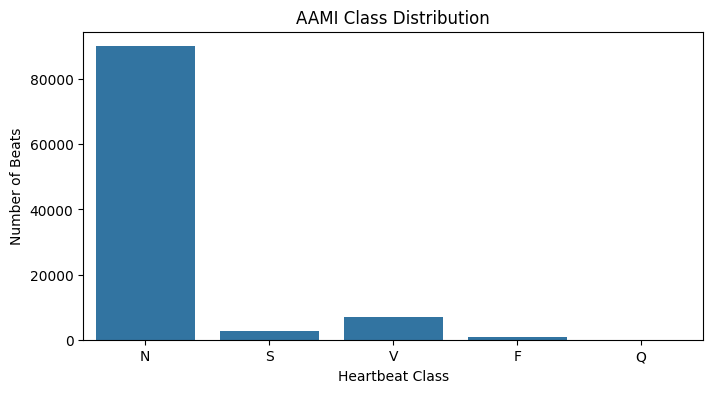

,Class,Count
0,N,90087
1,S,2781
2,V,7008
3,F,802
4,Q,15


In [8]:
counts = np.bincount(y, minlength=len(classes))

plt.figure(figsize=(8, 4))
sns.barplot(x=classes, y=counts)

plt.title("AAMI Class Distribution")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Beats")
plt.show()

distribution = pd.DataFrame({
    "Class": classes,
    "Count": counts
})

display(distribution)

Step 9 — Perform Inter-Patient Train, Validation and Test Split

In [9]:
splitter1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

trainval_idx, test_idx = next(
    splitter1.split(X, y, groups)
)

splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

tr_idx, val_idx = next(
    splitter2.split(
        X[trainval_idx],
        y[trainval_idx],
        groups[trainval_idx]
    )
)

train_idx = trainval_idx[tr_idx]
val_idx = trainval_idx[val_idx]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("Patient overlap (train/test):",
      set(groups[train_idx]) & set(groups[test_idx]))

print("Patient overlap (train/val):",
      set(groups[train_idx]) & set(groups[val_idx]))

print("Patient overlap (val/test):",
      set(groups[val_idx]) & set(groups[test_idx]))

Training: (62106, 256)
Validation: (18144, 256)
Testing: (20443, 256)
Patient overlap (train/test): set()
Patient overlap (train/val): set()
Patient overlap (val/test): set()


Step 10 — Normalize ECG Beats and Reshape Inputs

Train shape: (62106, 256, 1)
Validation shape: (18144, 256, 1)
Test shape: (20443, 256, 1)


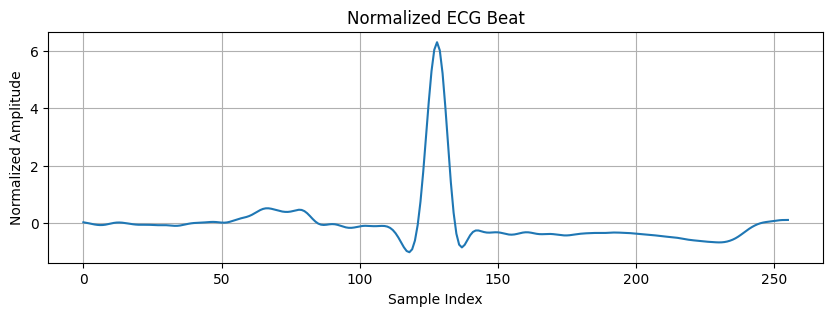

In [10]:
def normalize_beats(data):
    mean = np.mean(data, axis=1, keepdims=True)
    std = np.std(data, axis=1, keepdims=True)

    return (data - mean) / (std + 1e-8)

X_train = normalize_beats(X_train)
X_val = normalize_beats(X_val)
X_test = normalize_beats(X_test)

X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

plt.figure(figsize=(10, 3))
plt.plot(X_train[0, :, 0])
plt.title("Normalized ECG Beat")
plt.xlabel("Sample Index")
plt.ylabel("Normalized Amplitude")
plt.grid()
plt.show()

Task 3 — Model Training and Evaluation

Step 11 — Handle Class Imbalance

In [11]:
MAX_PER_CLASS = 20000

selected = []

for c in np.unique(y_train):
    idx = np.where(y_train == c)[0]

    if len(idx) > MAX_PER_CLASS:
        idx = np.random.choice(
            idx, MAX_PER_CLASS, replace=False
        )

    selected.extend(idx)

selected = np.array(selected)
np.random.shuffle(selected)

X_train = X_train[selected]
y_train = y_train[selected]

train_counts = np.bincount(
    y_train, minlength=len(classes)
)

present = np.where(train_counts > 0)[0]

class_weights = {
    int(c): float(
        len(y_train) /
        (len(present) * train_counts[c])
    )
    for c in present
}

print("Training class distribution:", train_counts)
print("Class weights:", class_weights)

Training class distribution: [20000  2157  3005    47     9]
Class weights: {0: 0.25218, 1: 2.338247566063978, 2: 1.6784026622296173, 3: 107.31063829787234, 4: 560.4}


Step 12 — Build RNN, LSTM and GRU Models

In [12]:
def build_model(model_type):
    model = Sequential()

    model.add(Input(shape=(256, 1)))

    if model_type == "RNN":
        model.add(SimpleRNN(64))

    elif model_type == "LSTM":
        model.add(LSTM(64))

    elif model_type == "GRU":
        model.add(GRU(64))

    model.add(Dropout(0.3))
    model.add(Dense(32, activation="relu"))
    model.add(Dense(5, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

models = {
    "RNN": build_model("RNN"),
    "LSTM": build_model("LSTM"),
    "GRU": build_model("GRU")
}

for name, model in models.items():
    print("\n", name, "Model")
    model.summary()


 RNN Model


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,469 (25.27 KB)

 Trainable params: 6,469 (25.27 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109 (59.02 KB)

 Trainable params: 15,109 (59.02 KB)

 Non-trainable params: 0 (0.00 B)

Step 13 — Train All Three Models with Early Stopping

In [13]:
histories = {}

for name, model in models.items():

    print("\nTraining:", name)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=256,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=1
    )

    histories[name] = history


Training: RNN
Epoch 1/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 16s 93ms/step - accuracy: 0.2133 - loss: 1.6169 - val_accuracy: 0.1519 - val_loss: 1.8609
Epoch 2/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.1786 - loss: 1.5598 - val_accuracy: 0.0769 - val_loss: 1.7975
Epoch 3/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.2166 - loss: 1.5293 - val_accuracy: 0.1496 - val_loss: 1.6683
Epoch 4/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.2587 - loss: 1.5232 - val_accuracy: 0.6403 - val_loss: 1.3626
Epoch 5/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.2135 - loss: 1.5312 - val_accuracy: 0.4332 - val_loss: 1.4703
Epoch 6/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.2905 - loss: 1.5948 - val_accuracy: 0.0491 - val_loss: 2.0474
Epoch 7/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.2301 - loss: 1.7400 - val_accuracy: 0.3931 - val_loss: 1.3683

Training: LSTM
Epoch 1/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.1326 - loss: 

Step 14 — Evaluate Accuracy, Precision, Recall, F1-Score and Confusion Matrices


 RNN Classification Report
              precision    recall  f1-score   support

           N       0.81      0.55      0.66     16802
           S       0.00      0.08      0.01       189
           V       0.02      0.02      0.02      3064
           F       0.04      0.03      0.03       386
           Q       0.00      0.00      0.00         2

    accuracy                           0.46     20443
   macro avg       0.17      0.14      0.14     20443
weighted avg       0.67      0.46      0.54     20443



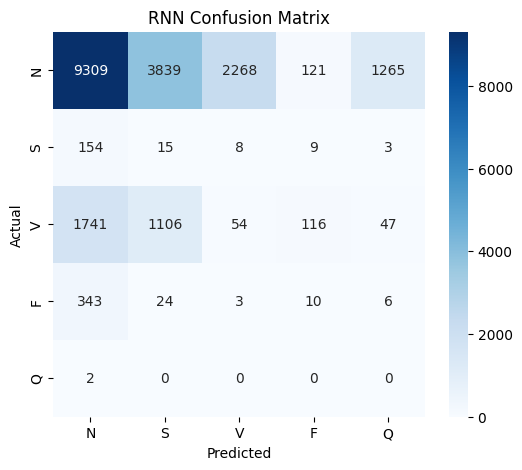


 LSTM Classification Report
              precision    recall  f1-score   support

           N       0.82      1.00      0.90     16802
           S       0.00      0.00      0.00       189
           V       0.00      0.00      0.00      3064
           F       0.00      0.00      0.00       386
           Q       0.00      0.00      0.00         2

    accuracy                           0.82     20443
   macro avg       0.16      0.20      0.18     20443
weighted avg       0.68      0.82      0.74     20443



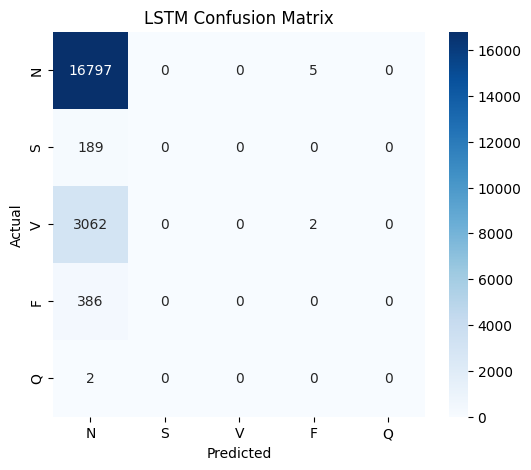


 GRU Classification Report
              precision    recall  f1-score   support

           N       0.58      0.13      0.21     16802
           S       0.00      0.14      0.01       189
           V       0.17      0.22      0.19      3064
           F       0.00      0.00      0.00       386
           Q       0.00      0.00      0.00         2

    accuracy                           0.14     20443
   macro avg       0.15      0.10      0.08     20443
weighted avg       0.50      0.14      0.20     20443



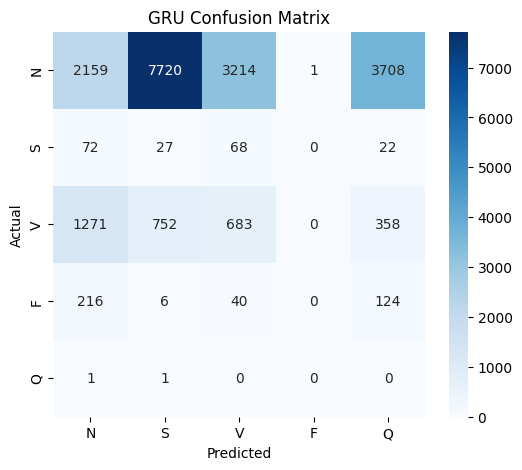

,Model,Accuracy,Precision,Recall,F1-Score
0,RNN,0.4592,0.1743,0.1354,0.1427
1,LSTM,0.8217,0.1644,0.1999,0.1804
2,GRU,0.1403,0.1508,0.0989,0.0820


In [14]:
results = []
predictions = {}

for name, model in models.items():

    y_pred = np.argmax(
        model.predict(X_test, verbose=0),
        axis=1
    )

    predictions[name] = y_pred

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_test,
            y_pred,
            labels=list(range(5)),
            average="macro",
            zero_division=0
        )
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\n", name, "Classification Report")

    print(classification_report(
        y_test,
        y_pred,
        labels=list(range(5)),
        target_names=classes,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test, y_pred, labels=list(range(5))
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

results_df = pd.DataFrame(results)
display(results_df.round(4))

Step 15 — Compare Models, Plot Learning Curves and Save Results

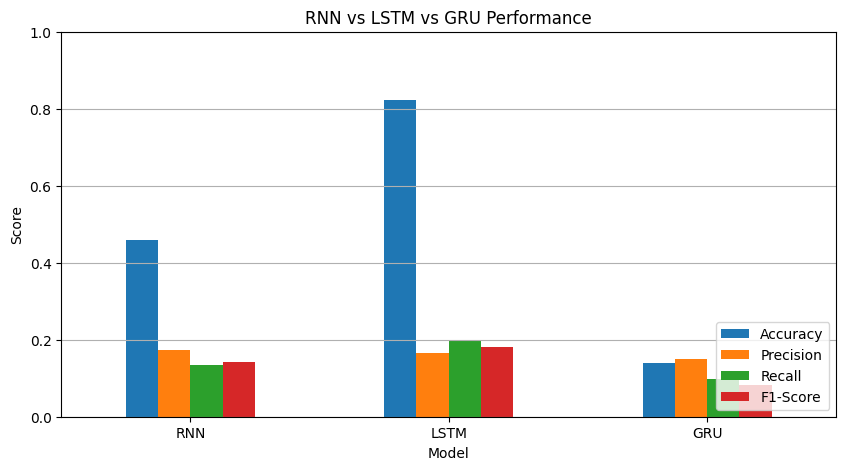

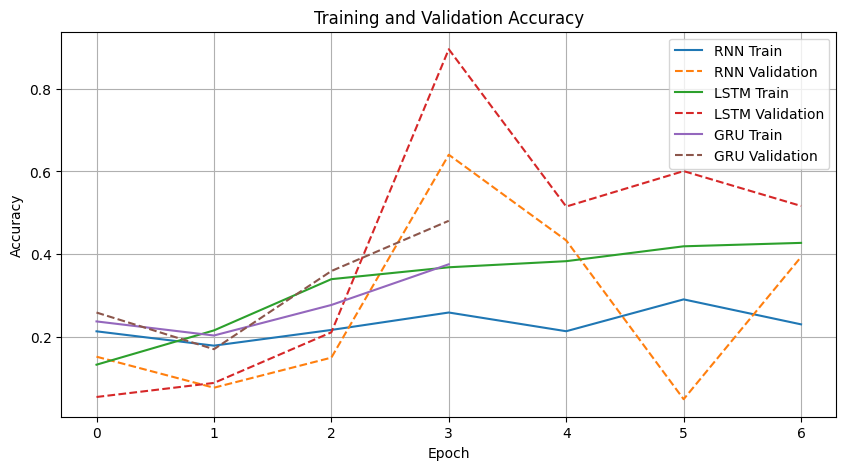

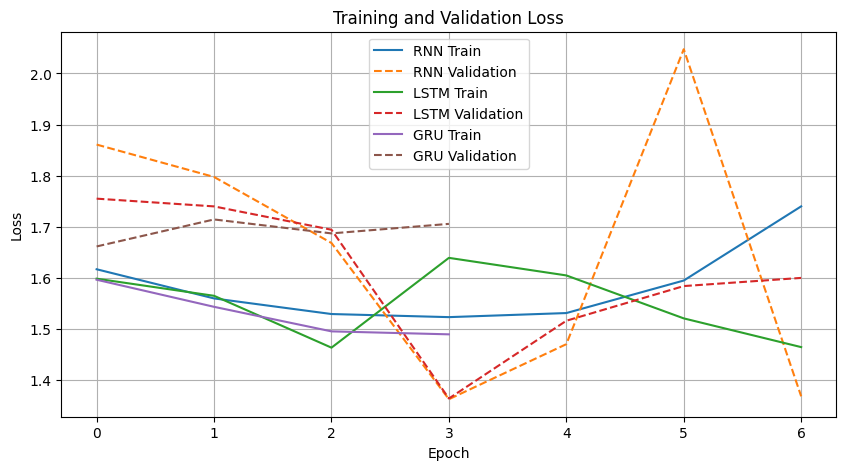

Best model by Macro F1:
Model            LSTM
Accuracy      0.82165
Precision    0.164386
Recall        0.19994
F1-Score     0.180429
Name: 1, dtype: object

Models and comparison CSV saved!


In [15]:
# Model comparison
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("RNN vs LSTM vs GRU Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.show()

# Training and validation accuracy
plt.figure(figsize=(10, 5))

for name, history in histories.items():
    plt.plot(
        history.history["accuracy"],
        label=name + " Train"
    )
    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=name + " Validation"
    )

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Training and validation loss
plt.figure(figsize=(10, 5))

for name, history in histories.items():
    plt.plot(
        history.history["loss"],
        label=name + " Train"
    )
    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=name + " Validation"
    )

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Save models and comparison results
for name, model in models.items():
    model.save(f"/content/{name}_arrhythmia.keras")

results_df.to_csv(
    "/content/model_comparison.csv",
    index=False
)

print("Best model by Macro F1:")
print(results_df.loc[
    results_df["F1-Score"].idxmax()
])

print("\nModels and comparison CSV saved!")